# Belguith Ahmed Rami — 22516111
# Benboubaker Majdi — 22517042

In [1]:
import os
import pandas as pd
import numpy as np


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import TextVectorization
from tensorflow.keras.utils import register_keras_serializable
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from keras.models import load_model
from tensorflow.keras.metrics import Mean
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.models import load_model

from UTILS import plot_training_curves

# Pour utiliser au mieux le GPU
AUTOTUNE = tf.data.AUTOTUNE

2026-01-18 16:13:37.929901: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/rami/miniconda3/lib/python3.12/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [2]:
# Classe utile pour la partie Clip mais il fallait bien regarder pour la trouver
@register_keras_serializable()
class L2Normalize(layers.Layer):
    def __init__(self, axis=-1, **kwargs):
        super().__init__(**kwargs)
        self.axis = axis

    def call(self, inputs):
        return tf.math.l2_normalize(inputs, axis=self.axis)

    def get_config(self):
        config = super().get_config()
        config.update({"axis": self.axis})
        return config

In [3]:
@register_keras_serializable()
class MaskedMean(layers.Layer):
  # Retourne la moyenne des mots sans être trop influencé par PAD
    def call(self, inputs):
        seq_out, token_ids = inputs   # (B,L,D), (B,L)
        mask = tf.cast(tf.not_equal(token_ids, 0), seq_out.dtype)  # PAD=0
        mask = tf.expand_dims(mask, -1)        # (B,L,1)
        summed = tf.reduce_sum(seq_out * mask, axis=1)             # (B,D)
        counts = tf.reduce_sum(mask, axis=1)                        # (B,1)
        return summed / tf.maximum(counts, 1.0)

In [4]:
# ============================
# PositionalEmbedding Layer
# ============================
@tf.keras.utils.register_keras_serializable()
class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.token_embeddings = layers.Embedding(input_dim=vocab_size,
                                                 output_dim=embed_dim)
        self.position_embeddings = layers.Embedding(input_dim=sequence_length,
                                                    output_dim=embed_dim)
        self.sequence_length = sequence_length
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim

    def call(self, inputs):
        length = tf.shape(inputs)[-1]
        positions = tf.range(0, length)
        embedded_tokens = self.token_embeddings(inputs)
        embedded_positions = self.position_embeddings(positions)
        return embedded_tokens + embedded_positions

    def compute_mask(self, inputs, mask=None):
        return tf.not_equal(inputs, 0)

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "vocab_size": self.vocab_size,
            "embed_dim": self.embed_dim,
        })
        return config

In [5]:
# ============================
# TransformerBlock
# ============================
@tf.keras.utils.register_keras_serializable()
class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads,ff_dim, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.supports_masking = True
        self.att = layers.MultiHeadAttention(num_heads=num_heads,
                                             key_dim=embed_dim)
        self.ffn = tf.keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim),
        ])
        self.layernorm1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)

    def call(self, inputs, training=False, mask=None):
        seq_len = tf.shape(inputs)[1]
        attn_mask = None
        if mask is not None:
            attn_mask = tf.cast(mask[:, tf.newaxis, :], dtype=tf.float32)
            attn_mask = tf.tile(attn_mask, [1, seq_len, 1])

        attn_output = self.att(inputs, inputs, inputs, attention_mask=attn_mask)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

        def get_config(self):
            config = super().get_config()
            config.update({
                "embed_dim": self.att.key_dim,
                "num_heads": self.att.num_heads,
                "ff_dim": self.ffn.layers[0].units,
                "dropout_rate": self.dropout1.rate,
            })
            return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)


# ============================
# SmallBERT encoder
# ============================
@register_keras_serializable()
class SmallBERT(tf.keras.Model):
    def __init__(self, sequence_length, vocab_size, embed_dim, num_heads,
                 ff_dim, num_layers, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.num_layers = num_layers

        self.pos_embedding = PositionalEmbedding(sequence_length, vocab_size,
                                                 embed_dim)

        self.transformer_blocks = [
            TransformerBlock(embed_dim,
                             num_heads, ff_dim) for _ in range(num_layers)
        ]
        self.layernorm = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.dropout = tf.keras.layers.Dropout(0.1)

    def call(self, inputs, training=False):
        x = self.pos_embedding(inputs)
        for block in self.transformer_blocks:
            x = block(x, training=training)
        x = self.layernorm(x)
        return self.dropout(x, training=training)

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "vocab_size": self.vocab_size,
            "embed_dim": self.embed_dim,
            "num_heads": self.num_heads,
            "ff_dim": self.ff_dim,
            "num_layers": self.num_layers,
        })
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)


# ============================================================
# 1) Tokenizer
# ============================================================

In [6]:
def build_and_adapt_tokenizer(captions_csv_path, vocab_size=10000, sequence_length=32):
    df = pd.read_csv(captions_csv_path)
    texts = df["caption"].fillna("").astype(str).tolist()

    tokenizer = TextVectorization(
        max_tokens=vocab_size,
        output_sequence_length=sequence_length,
        standardize="lower_and_strip_punctuation",
    )
    tokenizer.adapt(texts)
    return tokenizer


def save_vocab(tokenizer: TextVectorization, vocab_path: str):
    vocab = tokenizer.get_vocabulary()
    os.makedirs(os.path.dirname(vocab_path), exist_ok=True)
    with open(vocab_path, "w", encoding="utf-8") as f:
        for w in vocab:
            f.write(w + "\n")
    print("Vocab sauvegardé:", vocab_path)

# ============================================================
# 2) Dataset texte supervisé (caption -> label)
#    Hypothèse robuste: colonne "label"
#    Si aucune n'existe: on dérive le label depuis image_path (dossier parent)
# ============================================================

In [7]:
def _infer_label_column(df):
    for col in ["label"]:
        if col in df.columns:
            return col
    return None


def build_text_classification_dataset(
    captions_csv_path,
    tokenizer,
    sequence_length=32,
    batch_size=64,
    shuffle=True,
    seed=42,
    val_split=0.2
):
    df = pd.read_csv(captions_csv_path).copy()
    df["caption"] = df["caption"].fillna("").astype(str)

    label_col = _infer_label_column(df)
    if label_col is None:
        # dérive la classe depuis image_path : ".../images/<class>/xxx.jpg"
        if "image_path" not in df.columns:
            raise ValueError("Impossible d'inférer les labels: aucune colonne label/category/class et pas de image_path.")
        df["__label__"] = df["image_path"].astype(str).apply(lambda p: Path(p).parts[-2])
        label_col = "__label__"

    # Encodage labels -> int
    classes = sorted(df[label_col].unique().tolist())
    class_to_id = {c: i for i, c in enumerate(classes)}
    df["label_id"] = df[label_col].map(class_to_id).astype(int)

    # Split train/val
    rng = np.random.default_rng(seed)
    idx = np.arange(len(df))
    rng.shuffle(idx)
    cut = int(len(df) * (1.0 - val_split))
    train_idx, val_idx = idx[:cut], idx[cut:]

    def make_ds(sub_df):
        texts = sub_df["caption"].tolist()
        labels = sub_df["label_id"].to_numpy(dtype=np.int32)

        ds = tf.data.Dataset.from_tensor_slices((texts, labels))
        if shuffle:
            ds = ds.shuffle(buffer_size=len(texts), seed=seed, reshuffle_each_iteration=True)

        def map_fn(text, y):
            tokens = tf.cast(tokenizer(text), tf.int32)  # (L,)
            return tokens, y

        ds = ds.map(map_fn, num_parallel_calls=AUTOTUNE)
        ds = ds.batch(batch_size).prefetch(AUTOTUNE)
        return ds

    train_ds = make_ds(df.iloc[train_idx])
    val_ds = make_ds(df.iloc[val_idx])

    return train_ds, val_ds, classes, class_to_id


# ============================================================
# 3) Classifieur texte SmallBERT : Dense(4)+softmax
#    (Pooling = MaskedMean car pas de CLS)
# ============================================================

In [8]:
def build_text_classifier_smallbert(
    vocab_size,
    sequence_length,
    embed_dim=128,
    num_heads=4,
    ff_dim=256,
    num_layers=2,
    num_classes=4
):
    txt_in = layers.Input(shape=(sequence_length,), dtype="int32", name="text_tokens")

    bert = SmallBERT(
        sequence_length=sequence_length,
        vocab_size=vocab_size,
        embed_dim=embed_dim,
        num_heads=num_heads,
        ff_dim=ff_dim,
        num_layers=num_layers,
        name="smallbert"
    )

    seq = bert(txt_in)                                   # (B,L,D)
    pooled = MaskedMean(name="masked_mean")([seq, txt_in])  # (B,D)

    # MLP simple (baseline)
    x = layers.Dense(256, activation="relu", name="mlp_dense")(pooled)
    x = layers.Dropout(0.2)(x)

    out = layers.Dense(num_classes, activation="softmax", name="cls_head")(x)

    model = Model(txt_in, out, name="text_classifier_smallbert")
    return model

# ============================================================
# 4) Entraîner le classifieur (baseline) + sauvegarder
# ============================================================

In [9]:
def train_text_classifier(
    captions_csv_path,
    model_dir,
    vocab_size=10000,
    sequence_length=32,
    embed_dim=128,
    num_heads=4,
    ff_dim=256,
    num_layers=2,
    batch_size=64,
    epochs=8,
    lr=1e-4
):
    os.makedirs(model_dir, exist_ok=True)

    # Tokenizer + vocab sauvegarde (recommandé par l’énoncé)
    tokenizer = build_and_adapt_tokenizer(captions_csv_path, vocab_size, sequence_length)
    save_vocab(tokenizer, os.path.join(model_dir, "vocab.txt"))

    # Dataset supervisé
    train_ds, val_ds, classes, class_to_id = build_text_classification_dataset(
        captions_csv_path=captions_csv_path,
        tokenizer=tokenizer,
        sequence_length=sequence_length,
        batch_size=batch_size,
        val_split=0.2
    )
    num_classes = len(classes)
    print("Classes texte (ordre):", classes)

    # Modèle
    clf = build_text_classifier_smallbert(
        vocab_size=vocab_size,
        sequence_length=sequence_length,
        embed_dim=embed_dim,
        num_heads=num_heads,
        ff_dim=ff_dim,
        num_layers=num_layers,
        num_classes=num_classes
    )

    clf.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    ]

    history = clf.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks)

    best_val_acc = float(np.max(history.history.get("val_accuracy", [np.nan])))
    best_val_loss = float(np.min(history.history.get("val_loss", [np.nan])))
    print(f"Best val_accuracy={best_val_acc:.4f} | Best val_loss={best_val_loss:.4f}")

    # Sauvegarde classifieur
    clf_path = os.path.join(model_dir, "text_classifier_smallbert.keras")
    clf.save(clf_path)
    print("Classifieur texte sauvegardé:", clf_path)
    return clf, tokenizer, classes, class_to_id, history


# ============================================================
# 5) Conversion en encodeur texte CLIP (dérivé du classifieur)
#    - suppression tête softmax
#    - sortie Dense(embed_dim) sans activation
#    - L2Normalize
#    - embed_dim identique à l’image (à paramétrer)
# ============================================================

In [10]:
def build_text_encoder_from_classifier(
    text_classifier_smallbert,
    embed_dim=128,
    pooled_layer_name="masked_mean"
):
    """
    On repart de la représentation pooled (B,D) avant la tête de classification,
    puis on projette en embeddings CLIP + L2Normalize.
    """
    pooled = text_classifier_smallbert.get_layer(pooled_layer_name).output  # (B,D)

    emb = layers.Dense(embed_dim, activation=None, name="txt_embed")(pooled)
    emb = L2Normalize(name="txt_l2norm")(emb)

    encoder = Model(
        inputs=text_classifier_smallbert.input,
        outputs=emb,
        name="text_encoder"
    )
    return encoder

# ============================================================
# 6) Exemple d’usage
# ============================================================

I0000 00:00:1768749223.854469    4478 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2242 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650 Ti with Max-Q Design, pci bus id: 0000:01:00.0, compute capability: 7.5


Vocab sauvegardé: ./models_forclip/vocab.txt
Classes texte (ordre): ['ball', 'bike', 'dog', 'water']
Epoch 1/8


/home/rami/miniconda3/lib/python3.12/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'masked_mean' (of type MaskedMean) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
2026-01-18 16:13:54.149671: I external/local_xla/xla/service/service.cc:163] XLA service 0x789a24009250 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-01-18 16:13:54.149699: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce GTX 1650 Ti with Max-Q Design, Compute Capability 7.5
2026-01-18 16:13:54.333444: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-01-18 16:13:55.484470: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 

 1/10 ━━━━━━━━━━━━━━━━━━━━ 2:39 18s/step - accuracy: 0.2344 - loss: 1.4475

I0000 00:00:1768749245.088149    4547 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 366ms/step - accuracy: 0.2594 - loss: 1.4056 - val_accuracy: 0.3938 - val_loss: 1.3529
Epoch 2/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3859 - loss: 1.3173 - val_accuracy: 0.4563 - val_loss: 1.2995
Epoch 3/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5156 - loss: 1.2398 - val_accuracy: 0.5500 - val_loss: 1.2194
Epoch 4/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.6094 - loss: 1.1382 - val_accuracy: 0.6313 - val_loss: 1.1229
Epoch 5/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7266 - loss: 1.0042 - val_accuracy: 0.6438 - val_loss: 1.0027
Epoch 6/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7391 - loss: 0.8399 - val_accuracy: 0.6750 - val_loss: 0.8828
Epoch 7/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.7859 - loss: 0.6801 - val_accuracy: 0.7125 - val_loss: 0.7550
Epoch 8/8
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8422 - loss: 0.5240 - val_accuracy: 0.7563 - val_loss: 0.6713


... (2 outputs left out)

 Total params: 1,961,344 (7.48 MB)

 Trainable params: 1,961,344 (7.48 MB)

 Non-trainable params: 0 (0.00 B)

Text encoder output shape: (2, 128)


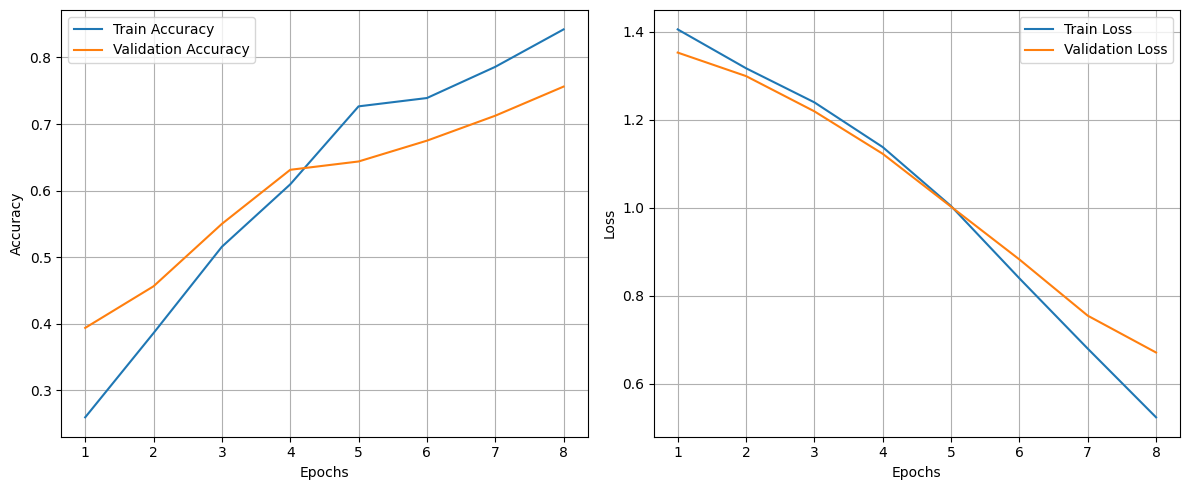

In [11]:
if __name__ == "__main__":
    dataset_dir = "./flickr_subset2/flickr_long_subset"
    captions_csv_path = os.path.join(dataset_dir, "captions.csv")
    model_dir = "./models_forclip"

    # Hyperparams (doivent matcher avec CLIP et l’image)
    sequence_length = 32
    vocab_size = 10000
    embed_dim = 128

    # 1) Entraîner classifieur texte
    text_clf, tokenizer, classes, class_to_id, history = train_text_classifier(
        captions_csv_path=captions_csv_path,
        model_dir=model_dir,
        vocab_size=vocab_size,
        sequence_length=sequence_length,
        embed_dim=embed_dim,
        epochs=8
    )

    # 2) Convertir en encodeur texte CLIP
    text_encoder = build_text_encoder_from_classifier(
        text_classifier_smallbert=text_clf,
        embed_dim=embed_dim,
        pooled_layer_name="masked_mean"
    )
    text_encoder.summary()

    # 3) Test shape
    sample = tf.constant(["a big dog in the woods", "a ball on the ground"])
    tokens = tokenizer(sample)  # (2, sequence_length)
    out = text_encoder(tokens)
    print("Text encoder output shape:", out.shape)  # (2, embed_dim)
    plot_training_curves(history, save_path=os.path.join(model_dir, "plot_text_classifier_training.png"))
